In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

In [3]:
# neural_root = '/home/wx2203/Weihao/data_locker/step_2/'
prefix = '/mnt/staging/' # or 

mouse='cm125'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

h5_root = step_3_root+mouse+'/dlc_h5s/'
video_root = step_3_root+mouse+'/dlc_movies/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'
face_h5_root = step_3_root+mouse+'/dlc_face_h5s/'
pupil_root = step_3_root

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

movement_sequence_root = str(PREPARES / "behavior-segment") + "/"


In [4]:
# files without random stim
f2 = list(set(glob.glob(step_2_root+"*125/[2]/H_runJ*.mat")) )

file_spont = f2
file_spont

['/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm125/2/H_runJ_stim_1.mat']

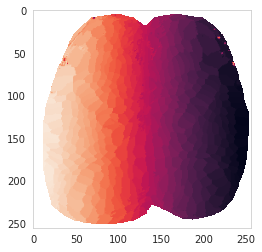

In [5]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [12]:

sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+mouse)
motor_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
mouth_S1_ind = sensory_ind['mouth']
extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse)
extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse)
sensory_ind['LM']=sensory_ind['mouth']
sensory_ind['RM']=extra_extra_ind['right_mouth_sensory']


In [13]:
big_df_concat =load_pickle(movement_sequence_root+'big_df_concat_'+mouse)

# only for cm125
big_df_concat['is_licking_paw']=np.logical_or(big_df_concat['is_groom_paw'],
                                              big_df_concat['is_groom_lick'])

all_bev_short_dict = {'whisk_vel_norm':'whisk_vel',
                     'pupil_pc_norm':'pupil_size',
                     'LFP_vel_norm':'LFP_vel',
                     'RFP_vel_norm':'RFP_vel',
                      'nose_vel_norm':'nose_vel',
                     'mirrorLFP_vel_norm':'mLFP_vel',
                     'mirrorRFP_vel_norm':'mRFP_vel',
                     'mirrorLHP_vel_norm':'mLHP_vel',
                     'mirrorRHP_vel_norm':'mRHP_vel',
                     'rot_raw':'rot'}

# load color
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# load midline
with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T

In [14]:
all_sessions = list(np.unique(big_df_concat.index.get_level_values(0)))
print(len(all_sessions),all_sessions)

30 ['cm125_1_runB', 'cm125_1_runC', 'cm125_1_runD', 'cm125_1_runE', 'cm125_1_runF', 'cm125_1_runG', 'cm125_1_runI', 'cm125_1_runJ', 'cm125_2_runB', 'cm125_2_runC', 'cm125_2_runD', 'cm125_2_runF', 'cm125_2_runG', 'cm125_2_runH', 'cm125_2_runI', 'cm125_2_runJ', 'cm125_3_runB', 'cm125_3_runC', 'cm125_3_runD', 'cm125_3_runE', 'cm125_3_runF', 'cm125_3_runG', 'cm125_3_runH', 'cm125_3_runI', 'cm125_3_runJ', 'cm125_4_runB', 'cm125_4_runC', 'cm125_4_runD', 'cm125_4_runH', 'cm125_4_runI']


In [15]:
big_df_concat

face_pc   body_pc  whisk_vel_norm  nose_vel_norm  \
row_level                                                               
cm125_4_runC 0      0.105055  0.005579        0.034632       0.120883   
             1      0.101733  0.011331        0.033775       0.121166   
             2      0.175736  0.012600        0.033371       0.122425   
             3      0.163552  0.013035        0.037040       0.125792   
             4      0.228231  0.011402        0.038498       0.123979   
...                      ...       ...             ...            ...   
cm125_3_runF 10970  0.780047  0.609777        0.564975       0.174185   
             10971  0.776919  0.649592        0.555386       0.170583   
             10972  0.737284  0.705456        0.554173       0.151260   
             10973  0.730545  0.726818        0.558346       0.140711   
             10974  0.651967  0.718781        0.593584       0.138040   

                    pupil_pc_norm  LFP_vel_norm  RFP_vel_norm  \
row_level                                                       
cm125_4_runC 0           0.000000      0.001522      0.001483   
             1           0.702642      0.001556      0.001443   
             2           0.700654      0.001571      0.001488   
             3           0.699042      0.001612      0.001524   
             4           0.689637      0.001520      0.001501   
...                           ...           ...           ...   
cm125_3_runF 10970       0.892590      0.385312      0.121837   
             10971       0.887411      0.375427      0.107792   
             10972       0.891062      0.362361      0.186217   
             10973       0.892426      0.340873      0.260411   
             10974       0.000000      0.303134      0.303593   

                    mirrorLFP_vel_norm  mirrorRFP_vel_norm  \
row_level                                                    
cm125_4_runC 0                0.001473            0.002504   
             1                0.001352            0.002610   
             2                0.001358            0.002633   
             3                0.001325            0.002620   
             4                0.001351            0.002709   
...                                ...                 ...   
cm125_3_runF 10970            0.341168            0.142644   
             10971            0.326674            0.138945   
             10972            0.300360            0.140376   
             10973            0.324776            0.142355   
             10974            0.295785            0.129456   

                    mirrorLHP_vel_norm  ...   rot_raw  rise_LFP  \
row_level                               ...                       
cm125_4_runC 0                0.000843  ...  0.213107  0.093051   
             1                0.000839  ...  0.212356  0.120987   
             2                0.000804  ...  0.212106  0.090753   
             3                0.000835  ...  0.212106  0.182443   
             4                0.000901  ...  0.212106  0.178778   
...                                ...  ...       ...       ...   
cm125_3_runF 10970            0.287571  ...  0.439614  5.995002   
             10971            0.288030  ...  0.415191  2.051652   
             10972            0.287945  ...  0.396940  1.433869   
             10973            0.288366  ...  0.382179  1.156089   
             10974            0.288615  ...  0.370639  0.947393   

                    is_groom_smooth_ds  is_rest  is_whisking  is_reach  \
row_level                                                                
cm125_4_runC 0                     0.0    False        False     False   
             1                     0.0    False        False     False   
             2                     0.0    False        False     False   
             3                     0.0    False        False     False   
             4                     0.0    False        False     False   
...                         

# load full data

In [16]:
i_sess = 15
session_name = all_sessions[i_sess] # H file in behavior2
mouse = session_name[:5];day=session_name[6];run_id=session_name[-4:]
mouseday_id = session_name[:7]

f3 = list(set(glob.glob(step_1_root+mouse+"/["+day+"]/*"+run_id+"*.mat")))[0]
with h5py.File(f3,'r') as f_H: 
    m = f_H['m']
    nanidx = np.squeeze(m['nanidx'])==1
    C = np.array(f_H['C']['jrgeco'])
    S = np.array(f_H['S']['jrgeco'])[500:-500,:]
    mask = np.array(f_H['mask'])
    # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
    CS = np.dot(S,C).transpose()
    jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
    jrgeco[:] = np.nan
    jrgeco[nanidx==True,:] = CS
    jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))

    # C = np.array(f_H['C']['chbt'])
    # S = np.array(f_H['S']['chbt'])
    # mask = np.array(f_H['mask'])
    # # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
    # CS = np.dot(S,C).transpose()
    # chbt = np.zeros((len(nanidx),CS.shape[-1]))
    # chbt[:] = np.nan
    # chbt[nanidx==True,:] = CS
    # chbt = chbt.reshape((256,256,-1)).transpose((1,0,2))
    
all_bev = ['whisk_vel_norm','nose_vel_norm','pupil_pc_norm','LFP_vel_norm','RFP_vel_norm','mirrorLHP_vel_norm',
           'mirrorRHP_vel_norm','rot_raw','face_pc','body_pc']
# all_bev = ['whisk_vel_norm','nose_vel_norm','pupil_pc_norm','RFP_vel_norm','mirrorLHP_vel_norm',
#            'rot_raw']
moseq_list = ['is_rest','is_whisking','is_reach','is_running','is_licking_paw']

all_bev_tc = {};all_moseq_tc={}
for i_bev, bev in enumerate(all_bev):
    # get behavior from big_df_concat
    all_bev_tc[bev] = np.array(big_df_concat.loc[session_name,bev])
for i_bev, bev in enumerate(moseq_list):
    # get moseq from big_df_concat
    all_moseq_tc[bev] = np.array(big_df_concat.loc[session_name,bev])

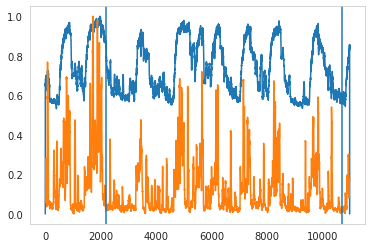

In [19]:
plt.plot(all_bev_tc['pupil_pc_norm'])
plt.plot(all_bev_tc['nose_vel_norm'])
plt.axvline(2200)
plt.axvline(10700)

In [20]:
cut_frames = range(2200,10700)
bsl_frames = range(2200,3000)
jrgeco = jrgeco[:,:,cut_frames]-np.mean(jrgeco[:,:,bsl_frames],axis=2)[:,:,np.newaxis]
# chbt = chbt[:,:,cut_frames]-np.mean(chbt[:,:,bsl_frames],axis=2)[:,:,np.newaxis]
# lime=lime[:,:,cut_frames]


In [21]:
mask_midline_array = np.repeat(mask_midline[:,:,np.newaxis],repeats=jrgeco.shape[-1],axis=2)
jrgeco = np.multiply(jrgeco,mask_midline_array)
# mask out the midline for jrgeco because we can't correct it
# chbt = np.multiply(chbt,mask_midline_array)



In [22]:
for i_bev, bev in enumerate(all_bev):
    all_bev_tc[bev] = all_bev_tc[bev][cut_frames] - np.mean(all_bev_tc[bev][bsl_frames])
for i_bev, bev in enumerate(moseq_list):
    all_moseq_tc[bev] = all_moseq_tc[bev][cut_frames]
    


In [23]:
choice_dict = {0:494,1:445,2:400,3:316,4:406} # cm125
# choice_dict = {0:482,1:446,2:379,3:344,4:396} # cm128
choice_body_part_dict = {0:'RM',
                   1:'RW',
                  2:'RFP',
                  3:'RHP',
                  4:'RV'}


In [24]:
# pre-compute
jrgeco2plot={};#chbt2plot={};
for iroi in choice_dict.keys():
    ind_roi = choice_dict[iroi]
    # mask = 1.0 * (IDX_sorted==motor_ind[ind_roi]+1) + np.nan*(IDX_sorted!=motor_ind[ind_roi]+1) 
    mask=np.ones((256,256));mask[:]=np.nan;
    mask[IDX_sorted==ind_roi+1]=1
    mask = np.repeat(mask[:,:,np.newaxis],repeats=jrgeco.shape[-1],axis=2)
    jrgeco2plot[ind_roi] = np.nanmean(np.nanmean(np.multiply(jrgeco,mask),axis=1),axis=0)

#     # mask = 1.0 * (IDX_sorted==sensory_ind[ind_roi]+1) + np.nan*(IDX_sorted!=sensory_ind[ind_roi]+1)
#     mask=np.ones((256,256));mask[:]=np.nan;
#     mask[IDX_sorted==ind_roi+1]=1
#     mask = np.repeat(mask[:,:,np.newaxis],repeats=chbt.shape[-1],axis=2)
#     chbt2plot[ind_roi] = np.nanmean(np.nanmean(np.multiply(chbt,mask),axis=1),axis=0)



/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:9: RuntimeWarning: Mean of empty slice
  if __name__ == '__main__':


In [25]:
full_data_dict = {'jrgeco':jrgeco}

In [26]:
from save_dict_to_hdf5 import *

In [27]:
# further trim to save space
trimmed_ind = np.r_[0:2300,5700:8500]
full_data_dict['jrgeco'] = full_data_dict['jrgeco'][:,:,trimmed_ind]
for key in jrgeco2plot:
    jrgeco2plot[key] = jrgeco2plot[key][trimmed_ind]
for key in all_bev_tc:
    all_bev_tc[key] = all_bev_tc[key][trimmed_ind]
for key in all_moseq_tc:
    all_moseq_tc[key] = all_moseq_tc[key][trimmed_ind]

In [28]:
save_dict = {'choice_dict':choice_dict,
             'choice_body_part_dict':choice_body_part_dict,
             'H_dict':jrgeco2plot,
             'full_data_dict':full_data_dict,
             'all_bev_tc':all_bev_tc,
             'all_moseq_tc':all_moseq_tc,
             'all_bev_short_dict':all_bev_short_dict,
             'run_id':'cm125_2_runJ',
}
             

In [30]:
def save_pickle(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file,protocol=4)

In [31]:
save_root = str(FIGURES / "figure2") + "/"

filename=save_root+'figure2_single_trial_example_cm125_2_runJ.pickle'
save_pickle(save_dict,filename)